In [1]:
# Show Plotly charts interactively in VS Code/Jupyter
# and save a static PNG copy so they also display on GitHub
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+png"

In [2]:

import pandas as pd
from sklearn.datasets import load_breast_cancer

# Load an established practice dataset
cancer = load_breast_cancer(as_frame=True)

# Extract features and target
X = cancer.data
y = cancer.target

# Display dataset information
print("DATASET SHAPE:", X.shape)
print("TARGET SHAPE:", y.shape)

print("\nTARGET CLASSES:")
print(dict(enumerate(cancer.target_names)))

print("\nFIRST FIVE RECORDS:")
display(X.head())

print("\nCLASS DISTRIBUTION:")
print(y.value_counts())


DATASET SHAPE: (569, 30)
TARGET SHAPE: (569,)

TARGET CLASSES:
{0: np.str_('malignant'), 1: np.str_('benign')}

FIRST FIVE RECORDS:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



CLASS DISTRIBUTION:
target
1    357
0    212
Name: count, dtype: int64


In [3]:

from sklearn.model_selection import train_test_split

# Split the dataset with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("TRAINING DATA")
print("Features:", X_train.shape)
print("Target:", y_train.shape)

print("\nTESTING DATA")
print("Features:", X_test.shape)
print("Target:", y_test.shape)

print("\nTRAINING CLASS DISTRIBUTION (%)")
print(y_train.value_counts(normalize=True).mul(100).round(1))

print("\nTESTING CLASS DISTRIBUTION (%)")
print(y_test.value_counts(normalize=True).mul(100).round(1))


TRAINING DATA
Features: (455, 30)
Target: (455,)

TESTING DATA
Features: (114, 30)
Target: (114,)

TRAINING CLASS DISTRIBUTION (%)
target
1    62.6
0    37.4
Name: proportion, dtype: float64

TESTING CLASS DISTRIBUTION (%)
target
1    63.2
0    36.8
Name: proportion, dtype: float64


In [4]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create the Machine Learning pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(max_iter=1000))
])

# Train the model using training data only
model.fit(X_train, y_train)

print("Pipeline trained successfully!")

# Predict outcomes for the testing dataset
y_pred = model.predict(X_test)

print("\nNumber of predictions:", len(y_pred))
print("First 10 predictions:", y_pred[:10].tolist())

print("\nFirst 10 actual outcomes:")
print(y_test.iloc[:10].tolist())


Pipeline trained successfully!



Number of predictions: 114
First 10 predictions: [0, 1, 0, 1, 0, 1, 1, 0, 0, 0]

First 10 actual outcomes:
[0, 1, 0, 1, 0, 1, 1, 0, 0, 0]


In [5]:

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Evaluate predictions on the testing dataset
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Rows: actual [malignant, benign]
# Columns: predicted [malignant, benign]
TP, FN = cm[0]
FP, TN = cm[1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=0)
recall = recall_score(y_test, y_pred, pos_label=0)
specificity = TN / (TN + FP)
f1 = f1_score(y_test, y_pred, pos_label=0)

print("CONFUSION MATRIX")
print(cm)

print("\nMODEL PERFORMANCE")
print(f"Accuracy: {accuracy:.2%}")
print(f"Precision (Malignant): {precision:.2%}")
print(f"Recall / Sensitivity (Malignant): {recall:.2%}")
print(f"Specificity: {specificity:.2%}")
print(f"F1-Score (Malignant): {f1:.3f}")

print("\nCLASSIFICATION COUNTS")
print("True Positives:", TP)
print("False Negatives:", FN)
print("False Positives:", FP)
print("True Negatives:", TN)


CONFUSION MATRIX
[[41  1]
 [ 1 71]]

MODEL PERFORMANCE
Accuracy: 98.25%
Precision (Malignant): 97.62%
Recall / Sensitivity (Malignant): 97.62%
Specificity: 98.61%
F1-Score (Malignant): 0.976

CLASSIFICATION COUNTS
True Positives: 41
False Negatives: 1
False Positives: 1
True Negatives: 71


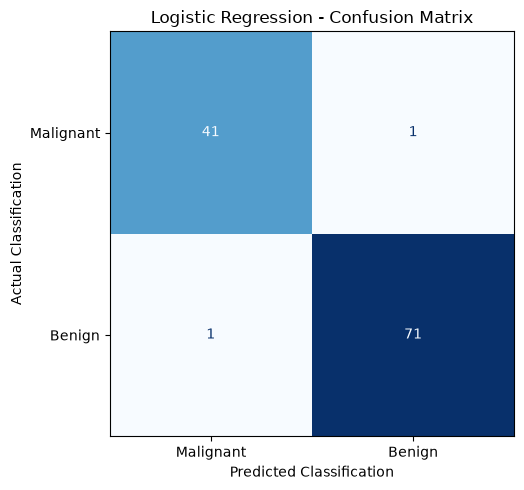

In [6]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Display the confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Logistic Regression - Confusion Matrix")
ax.set_xlabel("Predicted Classification")
ax.set_ylabel("Actual Classification")

plt.tight_layout()
plt.show()


In [7]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Create a Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train using the same training dataset
rf_model.fit(X_train, y_train)

# Predict using the same testing dataset
rf_pred = rf_model.predict(X_test)

print("Random Forest trained successfully!")

print("\nNumber of predictions:", len(rf_pred))

print("\nRANDOM FOREST CONFUSION MATRIX")
print(confusion_matrix(y_test, rf_pred, labels=[0, 1]))

print("\nRANDOM FOREST ACCURACY")
print(f"{accuracy_score(y_test, rf_pred):.2%}")

print("\nLOGISTIC REGRESSION ACCURACY")
print(f"{accuracy_score(y_test, y_pred):.2%}")


Random Forest trained successfully!

Number of predictions: 114

RANDOM FOREST CONFUSION MATRIX
[[39  3]
 [ 2 70]]

RANDOM FOREST ACCURACY
95.61%

LOGISTIC REGRESSION ACCURACY
98.25%


In [8]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def evaluate_model(name, actual, predicted):
    cm = confusion_matrix(actual, predicted, labels=[0, 1])

    TP, FN = cm[0]
    FP, TN = cm[1]

    return {
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(actual, predicted) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(actual, predicted, pos_label=0) * 100, 2
        ),
        "Sensitivity (%)": round(
            recall_score(actual, predicted, pos_label=0) * 100, 2
        ),
        "Specificity (%)": round(
            TN / (TN + FP) * 100, 2
        ),
        "F1-Score": round(
            f1_score(actual, predicted, pos_label=0), 3
        ),
        "False Negatives": int(FN)
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, y_pred),
    evaluate_model("Random Forest", y_test, rf_pred)
])

print("MODEL PERFORMANCE COMPARISON")
display(results)


MODEL PERFORMANCE COMPARISON


,Model,Accuracy (%),Precision (%),Sensitivity (%),Specificity (%),F1-Score,False Negatives
0,Logistic Regression,98.25,97.62,97.62,98.61,0.976,1
1,Random Forest,95.61,95.12,92.86,97.22,0.940,3


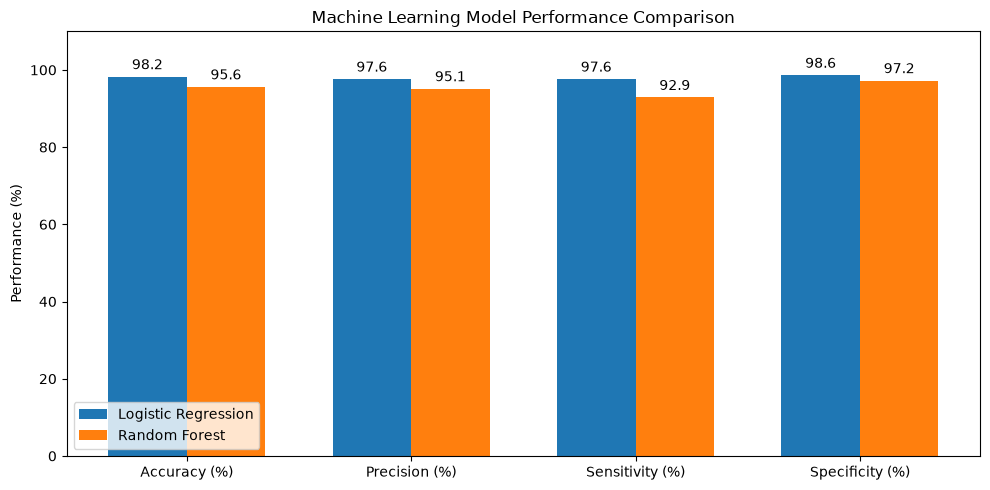

In [9]:

import matplotlib.pyplot as plt
import numpy as np

# Select performance indicators
metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Sensitivity (%)",
    "Specificity (%)"
]

# Extract results from our comparison table
logistic = results.loc[0, metrics].astype(float).to_numpy()
forest = results.loc[1, metrics].astype(float).to_numpy()

# Set bar positions
x = np.arange(len(metrics))
width = 0.35

# Create comparison chart
fig, ax = plt.subplots(figsize=(10, 5))

bars1 = ax.bar(
    x - width / 2,
    logistic,
    width,
    label="Logistic Regression"
)

bars2 = ax.bar(
    x + width / 2,
    forest,
    width,
    label="Random Forest"
)

# Add value labels
ax.bar_label(bars1, fmt="%.1f", padding=3)
ax.bar_label(bars2, fmt="%.1f", padding=3)

# Format chart
ax.set_title("Machine Learning Model Performance Comparison")
ax.set_ylabel("Performance (%)")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 110)
ax.legend()

plt.tight_layout()
plt.show()


In [10]:

import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Create five stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define Logistic Regression pipeline
lr_cv = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# Define Random Forest
rf_cv = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Evaluate both models on training data only
lr_scores = cross_val_score(
    lr_cv, X_train, y_train,
    cv=cv, scoring="accuracy"
)

rf_scores = cross_val_score(
    rf_cv, X_train, y_train,
    cv=cv, scoring="accuracy"
)

print("LOGISTIC REGRESSION")
print("Fold accuracies:", np.round(lr_scores, 4))
print(f"Mean accuracy: {lr_scores.mean():.2%}")
print(f"Standard deviation: {lr_scores.std():.4f}")

print("\nRANDOM FOREST")
print("Fold accuracies:", np.round(rf_scores, 4))
print(f"Mean accuracy: {rf_scores.mean():.2%}")
print(f"Standard deviation: {rf_scores.std():.4f}")


LOGISTIC REGRESSION
Fold accuracies: [0.967 0.989 0.978 0.989 0.967]
Mean accuracy: 97.80%
Standard deviation: 0.0098

RANDOM FOREST
Fold accuracies: [0.967  0.956  0.9341 0.967  0.989 ]
Mean accuracy: 96.26%
Standard deviation: 0.0179


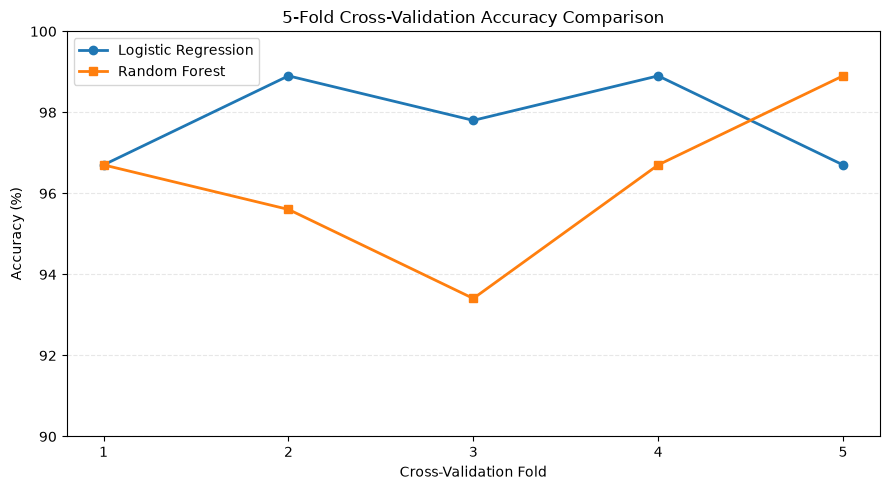

In [11]:

import matplotlib.pyplot as plt
import numpy as np

# Fold numbers
folds = np.arange(1, 6)

# Convert cross-validation accuracy to percentages
lr_accuracy = lr_scores * 100
rf_accuracy = rf_scores * 100

# Create the chart
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    folds,
    lr_accuracy,
    marker="o",
    linewidth=2,
    label="Logistic Regression"
)

ax.plot(
    folds,
    rf_accuracy,
    marker="s",
    linewidth=2,
    label="Random Forest"
)

# Format the chart
ax.set_title("5-Fold Cross-Validation Accuracy Comparison")
ax.set_xlabel("Cross-Validation Fold")
ax.set_ylabel("Accuracy (%)")
ax.set_xticks(folds)
ax.set_ylim(90, 100)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


TOP 10 IMPORTANT FEATURES


,Feature,Importance
23,worst area,0.140016
27,worst concave points,0.129530
20,worst radius,0.097696
7,mean concave points,0.090885
22,worst perimeter,0.072226
2,mean perimeter,0.069574
0,mean radius,0.068676
6,mean concavity,0.057638
3,mean area,0.049172
26,worst concavity,0.034340


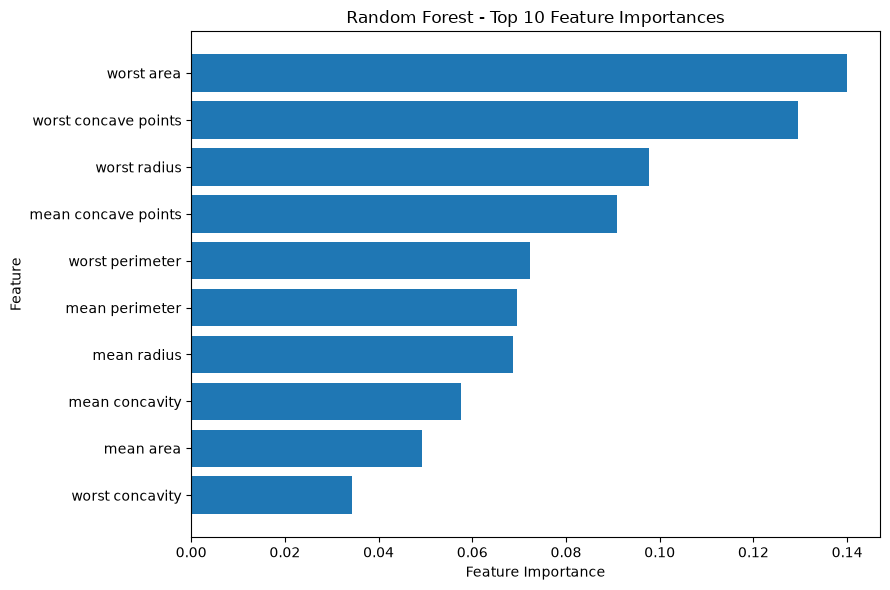

In [12]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Rank features
importance = importance.sort_values(
    "Importance",
    ascending=False
)

print("TOP 10 IMPORTANT FEATURES")
display(importance.head(10))

# Visualize the top 10
top10 = importance.head(10).sort_values("Importance")

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(top10["Feature"], top10["Importance"])

ax.set_title("Random Forest - Top 10 Feature Importances")
ax.set_xlabel("Feature Importance")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()


In [13]:

import pandas as pd
from sklearn.inspection import permutation_importance

# Calculate permutation importance on test data
perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy"
)

# Create a results table
perm_results = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean Importance": perm.importances_mean,
    "Std Deviation": perm.importances_std
})

# Rank features by importance
perm_results = perm_results.sort_values(
    "Mean Importance",
    ascending=False
)

print("TOP 10 PERMUTATION IMPORTANCES")
display(perm_results.head(10))


TOP 10 PERMUTATION IMPORTANCES


,Feature,Mean Importance,Std Deviation
15,compactness error,0.007895,0.002632
7,mean concave points,0.007895,0.007287
21,worst texture,0.007018,0.005263
23,worst area,0.007018,0.010230
3,mean area,0.005263,0.004297
4,mean smoothness,0.005263,0.004297
10,radius error,0.004386,0.004386
0,mean radius,0.004386,0.004386
17,concave points error,0.003509,0.004297
6,mean concavity,0.003509,0.004297


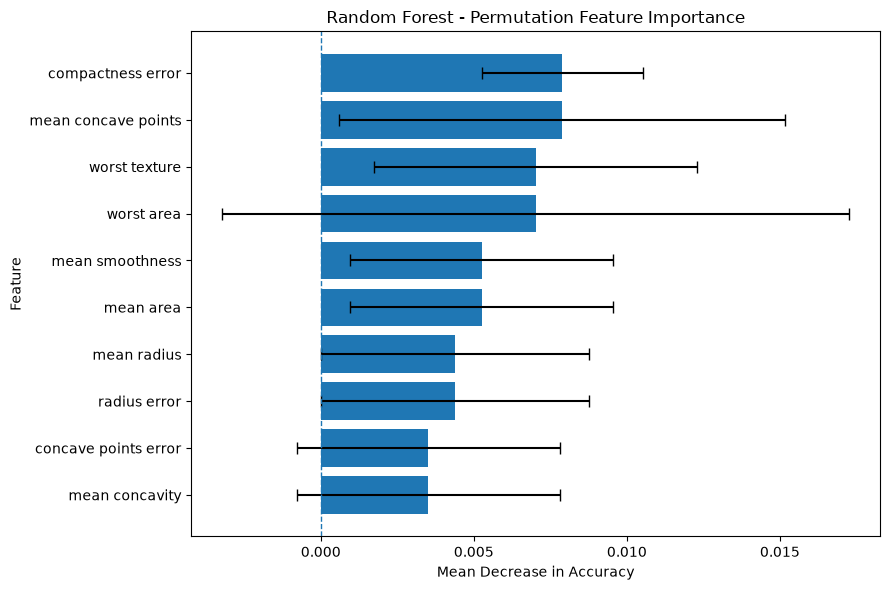

In [14]:

import matplotlib.pyplot as plt

# Select the top 10 features
top_perm = perm_results.head(10).sort_values(
    "Mean Importance"
)

# Create the chart
fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top_perm["Feature"],
    top_perm["Mean Importance"],
    xerr=top_perm["Std Deviation"],
    capsize=4
)

ax.set_title("Random Forest - Permutation Feature Importance")
ax.set_xlabel("Mean Decrease in Accuracy")
ax.set_ylabel("Feature")

# Reference line at zero
ax.axvline(0, linestyle="--", linewidth=1)

plt.tight_layout()
plt.show()


In [15]:

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define the model
rf = RandomForestClassifier(random_state=42)

# Define the hyperparameters to test
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5]
}

# Create grid search
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Search using training data only
grid_search.fit(X_train, y_train)

print("GRID SEARCH COMPLETED")

print("\nBEST PARAMETERS")
print(grid_search.best_params_)

print("\nBEST CROSS-VALIDATION ACCURACY")
print(f"{grid_search.best_score_:.2%}")

print("\nTOTAL PARAMETER COMBINATIONS")
print(len(grid_search.cv_results_["params"]))


GRID SEARCH COMPLETED

BEST PARAMETERS
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}

BEST CROSS-VALIDATION ACCURACY
96.04%

TOTAL PARAMETER COMBINATIONS
18


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

# Retrieve the best model from GridSearchCV
tuned_rf = grid_search.best_estimator_

# Generate predictions
tuned_pred = tuned_rf.predict(X_test)

# Compare the three models
models = {
    "Logistic Regression": y_pred,
    "Original Random Forest": rf_pred,
    "Tuned Random Forest": tuned_pred
}

comparison = []

for name, predictions in models.items():
    cm_model = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    TP, FN = cm_model[0]
    FP, TN = cm_model[1]

    comparison.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        "Sensitivity (%)": round(
            recall_score(y_test, predictions, pos_label=0) * 100, 2
        ),
        "Specificity (%)": round(
            TN / (TN + FP) * 100, 2
        ),
        "F1-Score": round(
            f1_score(y_test, predictions, pos_label=0), 3
        ),
        "False Negatives": int(FN)
    })

comparison_df = pd.DataFrame(comparison)

print("FINAL MODEL COMPARISON")
display(comparison_df)

print("\nTUNED RANDOM FOREST CONFUSION MATRIX")
print(confusion_matrix(y_test, tuned_pred, labels=[0, 1]))


FINAL MODEL COMPARISON


,Model,Accuracy (%),Sensitivity (%),Specificity (%),F1-Score,False Negatives
0,Logistic Regression,98.25,97.62,98.61,0.976,1
1,Original Random Forest,95.61,92.86,97.22,0.940,3
2,Tuned Random Forest,95.61,92.86,97.22,0.940,3



TUNED RANDOM FOREST CONFUSION MATRIX
[[39  3]
 [ 2 70]]


In [17]:

from sklearn.metrics import roc_auc_score

# Probability of malignant class (0)
lr_prob = model.predict_proba(X_test)[:, 0]
rf_prob = rf_model.predict_proba(X_test)[:, 0]
tuned_prob = tuned_rf.predict_proba(X_test)[:, 0]

# Create binary target: 1 = malignant
y_malignant = (y_test == 0).astype(int)

# Calculate ROC-AUC
lr_auc = roc_auc_score(y_malignant, lr_prob)
rf_auc = roc_auc_score(y_malignant, rf_prob)
tuned_auc = roc_auc_score(y_malignant, tuned_prob)

print("ROC-AUC COMPARISON")
print(f"Logistic Regression: {lr_auc:.4f}")
print(f"Original Random Forest: {rf_auc:.4f}")
print(f"Tuned Random Forest: {tuned_auc:.4f}")


ROC-AUC COMPARISON
Logistic Regression: 0.9954
Original Random Forest: 0.9937
Tuned Random Forest: 0.9931


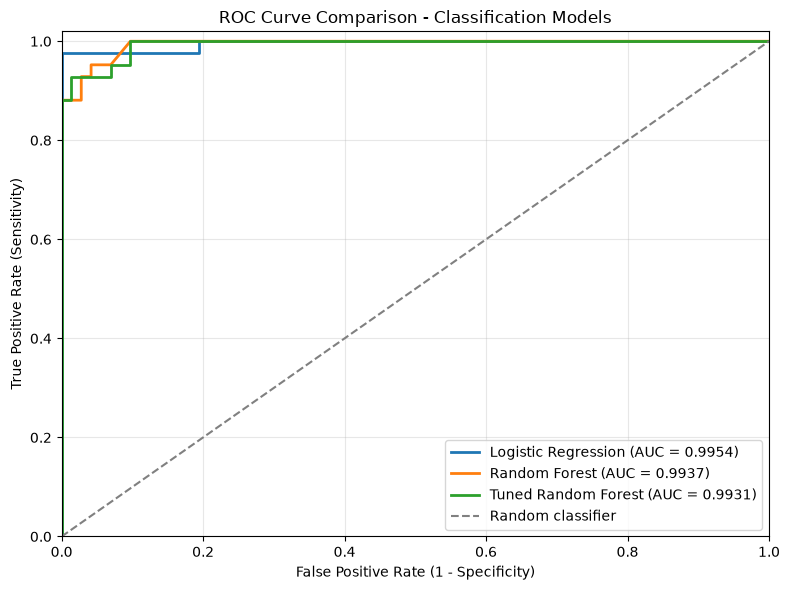

In [18]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# Calculate ROC curves
lr_fpr, lr_tpr, _ = roc_curve(y_malignant, lr_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_malignant, rf_prob)
tuned_fpr, tuned_tpr, _ = roc_curve(y_malignant, tuned_prob)

# Create the chart
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    lr_fpr, lr_tpr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {lr_auc:.4f})"
)

ax.plot(
    rf_fpr, rf_tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {rf_auc:.4f})"
)

ax.plot(
    tuned_fpr, tuned_tpr,
    linewidth=2,
    label=f"Tuned Random Forest (AUC = {tuned_auc:.4f})"
)

# Reference line for random discrimination
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

# Format chart
ax.set_title("ROC Curve Comparison - Classification Models")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


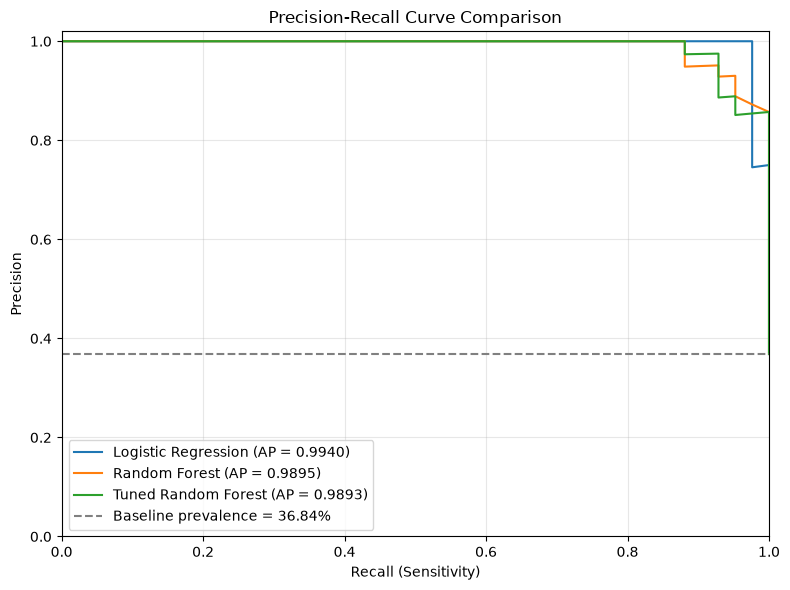

AVERAGE PRECISION SCORES
Logistic Regression: 0.9940
Random Forest: 0.9895
Tuned Random Forest: 0.9893


In [19]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Calculate precision-recall curves
lr_precision, lr_recall, _ = precision_recall_curve(
    y_malignant, lr_prob
)

rf_precision, rf_recall, _ = precision_recall_curve(
    y_malignant, rf_prob
)

tuned_precision, tuned_recall, _ = precision_recall_curve(
    y_malignant, tuned_prob
)

# Calculate average precision scores
lr_ap = average_precision_score(y_malignant, lr_prob)
rf_ap = average_precision_score(y_malignant, rf_prob)
tuned_ap = average_precision_score(y_malignant, tuned_prob)

# Plot the curves
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    lr_recall, lr_precision,
    label=f"Logistic Regression (AP = {lr_ap:.4f})"
)

ax.plot(
    rf_recall, rf_precision,
    label=f"Random Forest (AP = {rf_ap:.4f})"
)

ax.plot(
    tuned_recall, tuned_precision,
    label=f"Tuned Random Forest (AP = {tuned_ap:.4f})"
)

# Reference prevalence
prevalence = y_malignant.mean()
ax.axhline(
    prevalence,
    linestyle="--",
    color="gray",
    label=f"Baseline prevalence = {prevalence:.2%}"
)

ax.set_title("Precision-Recall Curve Comparison")
ax.set_xlabel("Recall (Sensitivity)")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower left")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("AVERAGE PRECISION SCORES")
print(f"Logistic Regression: {lr_ap:.4f}")
print(f"Random Forest: {rf_ap:.4f}")
print(f"Tuned Random Forest: {tuned_ap:.4f}")


In [20]:

import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score
)

# Test different probability thresholds
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

threshold_results = []

for threshold in thresholds:

    # Predict malignant when probability >= threshold
    predictions = (lr_prob >= threshold).astype(int)

    # Malignant = 1 in y_malignant
    tn, fp, fn, tp = confusion_matrix(
        y_malignant,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Sensitivity (%)": round(
            recall_score(y_malignant, predictions) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(
                y_malignant,
                predictions,
                zero_division=0
            ) * 100, 2
        ),
        "False Negatives": int(fn),
        "False Positives": int(fp)
    })

threshold_df = pd.DataFrame(threshold_results)

print("CLASSIFICATION THRESHOLD COMPARISON")
display(threshold_df)


CLASSIFICATION THRESHOLD COMPARISON


,Threshold,Sensitivity (%),Precision (%),False Negatives,False Positives
0,0.2,97.62,87.23,1,6
1,0.3,97.62,89.13,1,5
2,0.4,97.62,91.11,1,4
3,0.5,97.62,97.62,1,1
4,0.6,97.62,97.62,1,1
5,0.7,95.24,100.00,2,0
6,0.8,95.24,100.00,2,0


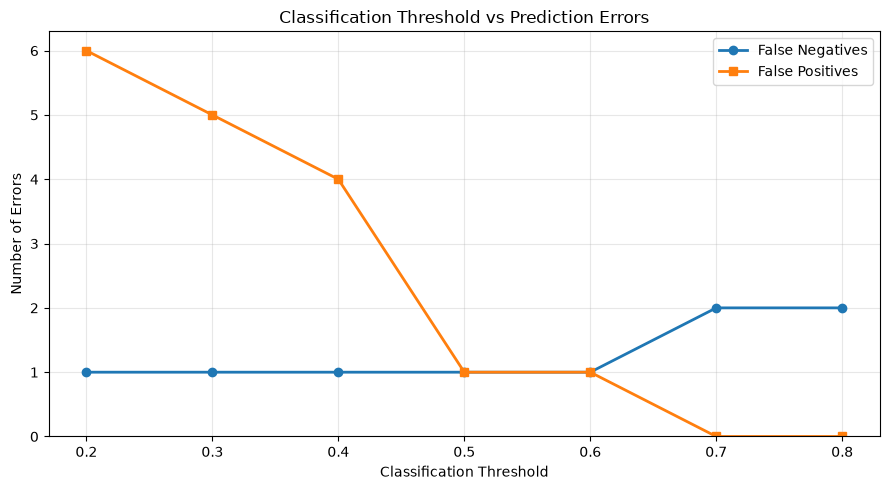

In [21]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    threshold_df["Threshold"],
    threshold_df["False Negatives"],
    marker="o",
    linewidth=2,
    label="False Negatives"
)

ax.plot(
    threshold_df["Threshold"],
    threshold_df["False Positives"],
    marker="s",
    linewidth=2,
    label="False Positives"
)

ax.set_title("Classification Threshold vs Prediction Errors")
ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Number of Errors")
ax.set_xticks(threshold_df["Threshold"])
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


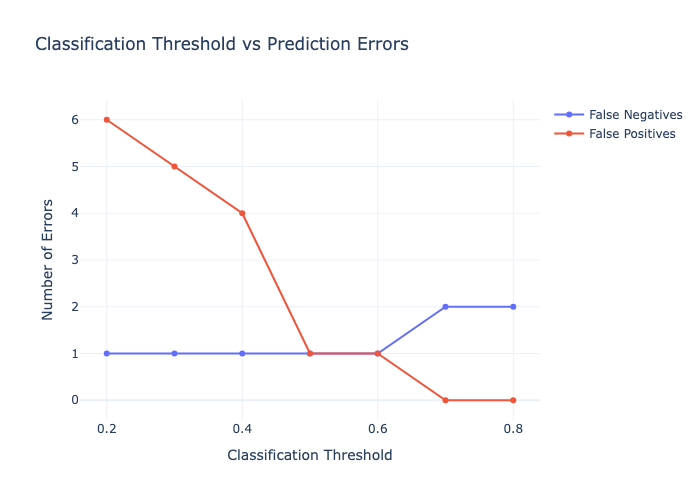

In [22]:
import plotly.graph_objects as go

fig = go.Figure()

# False Negatives
fig.add_trace(go.Scatter(
    x=threshold_df["Threshold"],
    y=threshold_df["False Negatives"],
    mode="lines+markers",
    name="False Negatives",
    hovertemplate="Threshold: %{x:.1f}<br>False Negatives: %{y}<extra></extra>"
))

# False Positives
fig.add_trace(go.Scatter(
    x=threshold_df["Threshold"],
    y=threshold_df["False Positives"],
    mode="lines+markers",
    name="False Positives",
    hovertemplate="Threshold: %{x:.1f}<br>False Positives: %{y}<extra></extra>"
))

fig.update_layout(
    title="Classification Threshold vs Prediction Errors",
    xaxis_title="Classification Threshold",
    yaxis_title="Number of Errors",
    template="plotly_white",
    hovermode="closest"
)

fig.show()

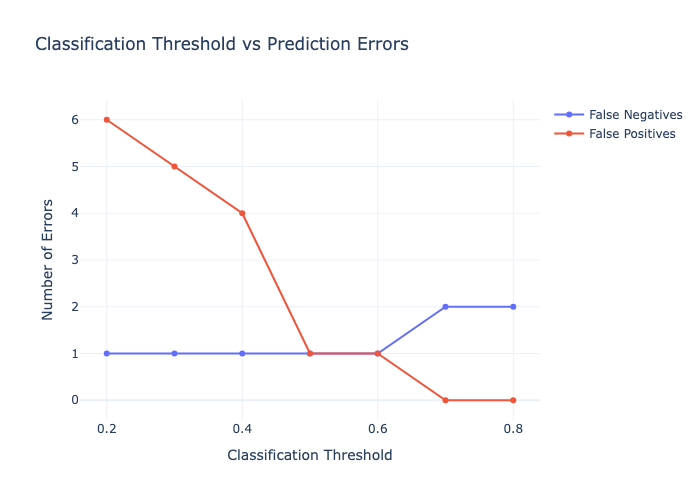

In [23]:
import plotly.graph_objects as go

fig = go.Figure()

# False Negatives
fig.add_trace(go.Scatter(
    x=threshold_df["Threshold"],
    y=threshold_df["False Negatives"],
    mode="lines+markers",
    name="False Negatives",
    hovertemplate="Threshold: %{x:.1f}<br>False Negatives: %{y}<extra></extra>"
))

# False Positives
fig.add_trace(go.Scatter(
    x=threshold_df["Threshold"],
    y=threshold_df["False Positives"],
    mode="lines+markers",
    name="False Positives",
    hovertemplate="Threshold: %{x:.1f}<br>False Positives: %{y}<extra></extra>"
))

fig.update_layout(
    title="Classification Threshold vs Prediction Errors",
    xaxis_title="Classification Threshold",
    yaxis_title="Number of Errors",
    template="plotly_white",
    hovermode="closest"
)

fig.show()

In [24]:
# Lesson 6: Cost-sensitive threshold evaluation

cost_df = threshold_df.copy()

# Hypothetical cost weights
fn_cost = 10
fp_cost = 1

# Calculate total cost for each threshold
cost_df["Total Cost"] = (
    cost_df["False Negatives"] * fn_cost
    + cost_df["False Positives"] * fp_cost
)

# Display results
print(cost_df[
    ["Threshold", "False Negatives",
     "False Positives", "Total Cost"]
].to_string(index=False))

# Identify the lowest-cost threshold
best_cost = cost_df["Total Cost"].min()

best_thresholds = cost_df.loc[
    cost_df["Total Cost"] == best_cost,
    "Threshold"
].tolist()

print("\nLowest total cost:", best_cost)
print("Threshold(s) with lowest cost:", best_thresholds)

 Threshold  False Negatives  False Positives  Total Cost
       0.2                1                6          16
       0.3                1                5          15
       0.4                1                4          14
       0.5                1                1          11
       0.6                1                1          11
       0.7                2                0          20
       0.8                2                0          20

Lowest total cost: 11
Threshold(s) with lowest cost: [0.5, 0.6]


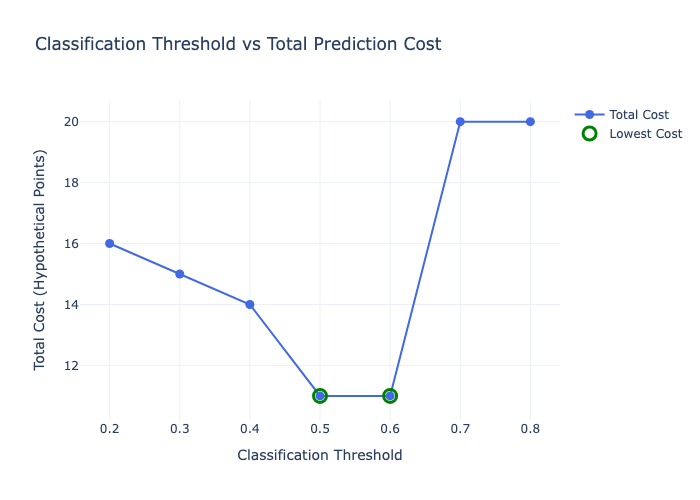

In [25]:
import plotly.graph_objects as go

fig = go.Figure()

# Plot total cost for each threshold
fig.add_trace(go.Scatter(
    x=cost_df["Threshold"],
    y=cost_df["Total Cost"],
    mode="lines+markers",
    name="Total Cost",
    line=dict(color="royalblue", width=2),
    marker=dict(size=9),
    hovertemplate=(
        "Threshold: %{x:.1f}<br>"
        "Total Cost: %{y}<extra></extra>"
    )
))

# Highlight the lowest-cost thresholds
best_rows = cost_df[
    cost_df["Total Cost"] == best_cost
]

fig.add_trace(go.Scatter(
    x=best_rows["Threshold"],
    y=best_rows["Total Cost"],
    mode="markers",
    name="Lowest Cost",
    marker=dict(
        color="green",
        size=13,
        symbol="circle-open",
        line=dict(width=3)
    ),
    hovertemplate=(
        "Optimal tested threshold: %{x:.1f}<br>"
        "Minimum Cost: %{y}<extra></extra>"
    )
))

fig.update_layout(
    title="Classification Threshold vs Total Prediction Cost",
    xaxis_title="Classification Threshold",
    yaxis_title="Total Cost (Hypothetical Points)",
    template="plotly_white",
    hovermode="closest"
)

fig.show()

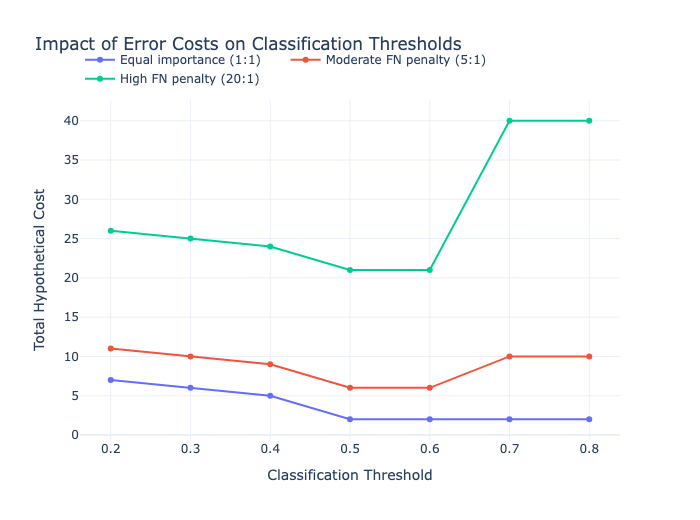

In [26]:
import plotly.graph_objects as go

scenarios = {
    "Equal importance (1:1)": (1, 1),
    "Moderate FN penalty (5:1)": (5, 1),
    "High FN penalty (20:1)": (20, 1)
}

fig = go.Figure()

for scenario, (fn_weight, fp_weight) in scenarios.items():

    total_cost = (
        threshold_df["False Negatives"] * fn_weight
        + threshold_df["False Positives"] * fp_weight
    )

    fig.add_trace(go.Scatter(
        x=threshold_df["Threshold"],
        y=total_cost,
        mode="lines+markers",
        name=scenario,
        customdata=threshold_df[
            ["False Negatives", "False Positives"]
        ].to_numpy(),
        hovertemplate=(
            "<b>%{fullData.name}</b><br>"
            "Threshold: %{x:.1f}<br>"
            "Total Cost: %{y}<br>"
            "False Negatives: %{customdata[0]}<br>"
            "False Positives: %{customdata[1]}"
            "<extra></extra>"
        )
    ))

fig.update_layout(
    title="Impact of Error Costs on Classification Thresholds",
    xaxis_title="Classification Threshold",
    yaxis_title="Total Hypothetical Cost",
    template="plotly_white",
    hovermode="x unified",
    hoverlabel=dict(font_size=12),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    height=520
)

fig.show()

In [27]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

results = []

for threshold in np.arange(0.01, 1.00, 0.01):

    predictions = (lr_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_malignant,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = (fn * 10) + (fp * 1)

    results.append({
        "Threshold": round(threshold, 2),
        "False Negatives": fn,
        "False Positives": fp,
        "Total Cost": total_cost
    })

optimization_df = pd.DataFrame(results)

minimum_cost = optimization_df["Total Cost"].min()

best_results = optimization_df[
    optimization_df["Total Cost"] == minimum_cost
]

print("Minimum hypothetical cost:", minimum_cost)
print("\nBest threshold(s):")
print(best_results.to_string(index=False))

Minimum hypothetical cost: 10

Best threshold(s):
 Threshold  False Negatives  False Positives  Total Cost
      0.64                1                0          10


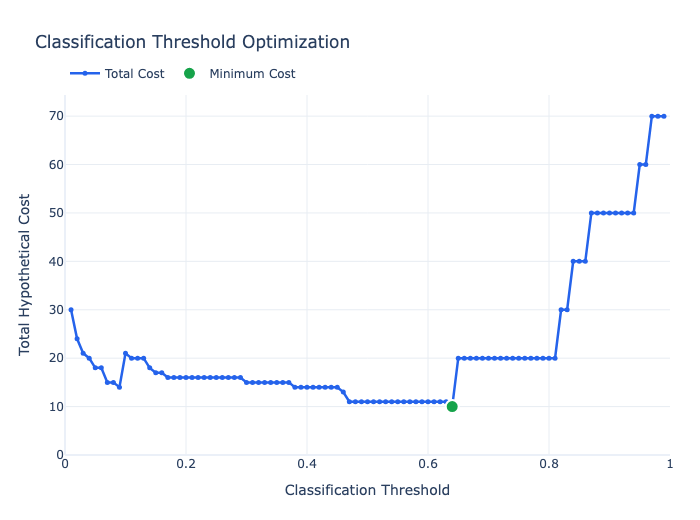

In [28]:
import plotly.graph_objects as go

fig = go.Figure()

# Full threshold optimization curve
fig.add_trace(go.Scatter(
    x=optimization_df["Threshold"],
    y=optimization_df["Total Cost"],
    mode="lines+markers",
    name="Total Cost",
    line=dict(color="#2563EB", width=2.5),
    marker=dict(size=5),
    customdata=optimization_df[
        ["False Negatives", "False Positives"]
    ].to_numpy(),
    hovertemplate=(
        "<b>Threshold: %{x:.2f}</b><br>"
        "Total Cost: %{y}<br>"
        "False Negatives: %{customdata[0]}<br>"
        "False Positives: %{customdata[1]}"
        "<extra></extra>"
    )
))

# Highlight lowest-cost threshold(s)
fig.add_trace(go.Scatter(
    x=best_results["Threshold"],
    y=best_results["Total Cost"],
    mode="markers",
    name="Minimum Cost",
    marker=dict(
        color="#16A34A",
        size=13,
        symbol="circle",
        line=dict(color="white", width=2)
    ),
    hovertemplate=(
        "<b>Best Tested Threshold</b><br>"
        "Threshold: %{x:.2f}<br>"
        "Minimum Cost: %{y}"
        "<extra></extra>"
    )
))

fig.update_layout(
    title="Classification Threshold Optimization",
    xaxis_title="Classification Threshold",
    yaxis_title="Total Hypothetical Cost",
    template="plotly_white",
    hovermode="closest",
    hoverlabel=dict(font_size=13),
    height=520,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    margin=dict(l=65, r=30, t=95, b=65)
)

fig.update_xaxes(
    showgrid=True,
    gridcolor="#E8EDF3",
    range=[0, 1]
)

fig.update_yaxes(
    showgrid=True,
    gridcolor="#E8EDF3",
    rangemode="tozero"
)

fig.show()

In [29]:
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Training observations: 455
Test observations: 114

Training class distribution:
target
1    285
0    170
Name: count, dtype: int64

Test class distribution:
target
1    72
0    42
Name: count, dtype: int64


In [30]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone
import numpy as np

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold probabilities using Logistic Regression
cv_probabilities = cross_val_predict(
    clone(model),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)

# Probability of malignant class (class 0)
cv_malignant_prob = cv_probabilities[:, 0]

# Actual malignant outcomes
cv_y_malignant = (y_train == 0).astype(int)

print("Cross-validated predictions:", len(cv_malignant_prob))
print("Minimum probability:", round(cv_malignant_prob.min(), 4))
print("Maximum probability:", round(cv_malignant_prob.max(), 4))
print("Actual malignant cases:", cv_y_malignant.sum())

Cross-validated predictions: 455
Minimum probability: 0.0
Maximum probability: 1.0
Actual malignant cases: 170


In [31]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

cv_results = []

# Evaluate thresholds from 0.01 to 0.99
for threshold in np.arange(0.01, 1.00, 0.01):

    predictions = (
        cv_malignant_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        cv_y_malignant,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = (fn * 10) + (fp * 1)

    cv_results.append({
        "Threshold": round(threshold, 2),
        "False Negatives": fn,
        "False Positives": fp,
        "Total Cost": total_cost
    })

cv_optimization_df = pd.DataFrame(cv_results)

# Find minimum cost
cv_min_cost = cv_optimization_df["Total Cost"].min()

# Identify all thresholds achieving minimum cost
cv_best_results = cv_optimization_df[
    cv_optimization_df["Total Cost"] == cv_min_cost
]

print("Minimum cross-validated cost:", cv_min_cost)

print("\nBest threshold(s):")
print(cv_best_results.to_string(index=False))

Minimum cross-validated cost: 36

Best threshold(s):
 Threshold  False Negatives  False Positives  Total Cost
      0.09                1               26          36


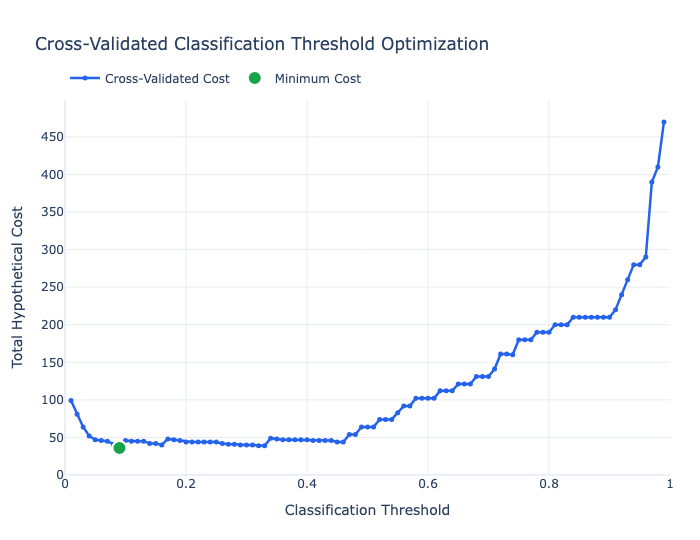

In [32]:
import plotly.graph_objects as go

fig = go.Figure()

# Cross-validated total cost
fig.add_trace(go.Scatter(
    x=cv_optimization_df["Threshold"],
    y=cv_optimization_df["Total Cost"],
    mode="lines+markers",
    name="Cross-Validated Cost",
    line=dict(color="#2563EB", width=2.5),
    marker=dict(size=5),
    customdata=cv_optimization_df[
        ["False Negatives", "False Positives"]
    ].to_numpy(),
    hovertemplate=(
        "<b>Threshold: %{x:.2f}</b><br>"
        "Total Cost: %{y}<br>"
        "False Negatives: %{customdata[0]}<br>"
        "False Positives: %{customdata[1]}"
        "<extra></extra>"
    )
))

# Highlight the minimum-cost threshold
fig.add_trace(go.Scatter(
    x=cv_best_results["Threshold"],
    y=cv_best_results["Total Cost"],
    mode="markers",
    name="Minimum Cost",
    marker=dict(
        color="#16A34A",
        size=14,
        line=dict(color="white", width=2)
    ),
    hovertemplate=(
        "<b>Best Cross-Validated Threshold</b><br>"
        "Threshold: %{x:.2f}<br>"
        "Total Cost: %{y}"
        "<extra></extra>"
    )
))

fig.update_layout(
    title="Cross-Validated Classification Threshold Optimization",
    xaxis_title="Classification Threshold",
    yaxis_title="Total Hypothetical Cost",
    template="plotly_white",
    hovermode="closest",
    hoverlabel=dict(font_size=13),
    height=540,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    margin=dict(l=65, r=30, t=100, b=65)
)

fig.update_xaxes(
    range=[0, 1],
    showgrid=True,
    gridcolor="#E8EDF3"
)

fig.update_yaxes(
    rangemode="tozero",
    showgrid=True,
    gridcolor="#E8EDF3"
)

fig.show()

In [33]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Threshold selected using training-data cross-validation
selected_threshold = float(
    cv_best_results["Threshold"].iloc[0]
)

# Apply the threshold to held-out test probabilities
test_predictions = (
    lr_prob >= selected_threshold
).astype(int)

# Confusion matrix: malignant is our positive class
tn, fp, fn, tp = confusion_matrix(
    y_malignant,
    test_predictions,
    labels=[0, 1]
).ravel()

# Calculate evaluation metrics
accuracy = accuracy_score(y_malignant, test_predictions)
sensitivity = recall_score(y_malignant, test_predictions)
specificity = tn / (tn + fp)
precision = precision_score(
    y_malignant, test_predictions, zero_division=0
)
f1 = f1_score(y_malignant, test_predictions)

# Hypothetical total cost
test_cost = (fn * 10) + fp

print("SELECTED THRESHOLD:", selected_threshold)
print("\nCONFUSION MATRIX")
print("True Positives:", tp)
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)

print("\nMODEL PERFORMANCE")
print(f"Accuracy:    {accuracy:.2%}")
print(f"Sensitivity: {sensitivity:.2%}")
print(f"Specificity: {specificity:.2%}")
print(f"Precision:   {precision:.2%}")
print(f"F1 Score:    {f1:.3f}")

print("\nHypothetical Test Cost:", test_cost)

SELECTED THRESHOLD: 0.09

CONFUSION MATRIX
True Positives: 42
True Negatives: 58
False Positives: 14
False Negatives: 0

MODEL PERFORMANCE
Accuracy:    87.72%
Sensitivity: 100.00%
Specificity: 80.56%
Precision:   75.00%
F1 Score:    0.857

Hypothetical Test Cost: 14


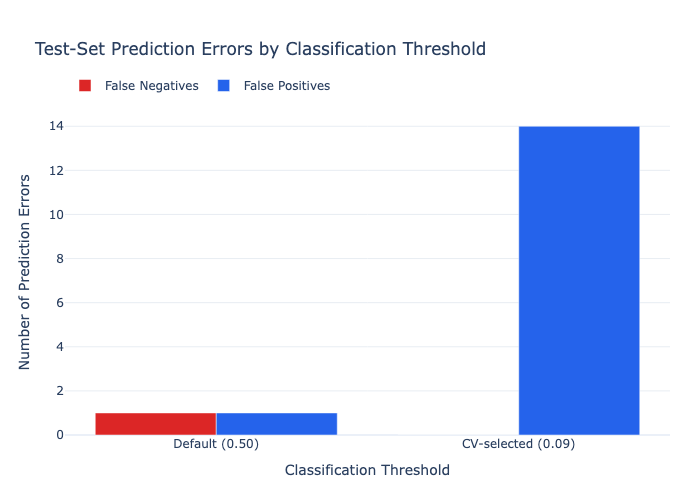

In [34]:
import pandas as pd
import plotly.graph_objects as go

comparison_df = pd.DataFrame({
    "Threshold": ["Default (0.50)", "CV-selected (0.09)"],
    "False Negatives": [1, fn],
    "False Positives": [1, fp]
})

fig = go.Figure()

for metric, color in [
    ("False Negatives", "#DC2626"),
    ("False Positives", "#2563EB")
]:
    fig.add_trace(go.Bar(
        x=comparison_df["Threshold"],
        y=comparison_df[metric],
        name=metric,
        marker_color=color,
        hovertemplate=(
            "<b>%{x}</b><br>"
            + metric + ": %{y}<extra></extra>"
        )
    ))

fig.update_layout(
    title="Test-Set Prediction Errors by Classification Threshold",
    xaxis_title="Classification Threshold",
    yaxis_title="Number of Prediction Errors",
    barmode="group",
    template="plotly_white",
    hovermode="x unified",
    hoverlabel=dict(font_size=13),
    height=500,
    legend=dict(
        orientation="h",
        y=1.12,
        x=0
    ),
    margin=dict(l=65, r=30, t=110, b=65)
)

fig.update_yaxes(
    dtick=2,
    rangemode="tozero",
    gridcolor="#E8EDF3"
)

fig.show()

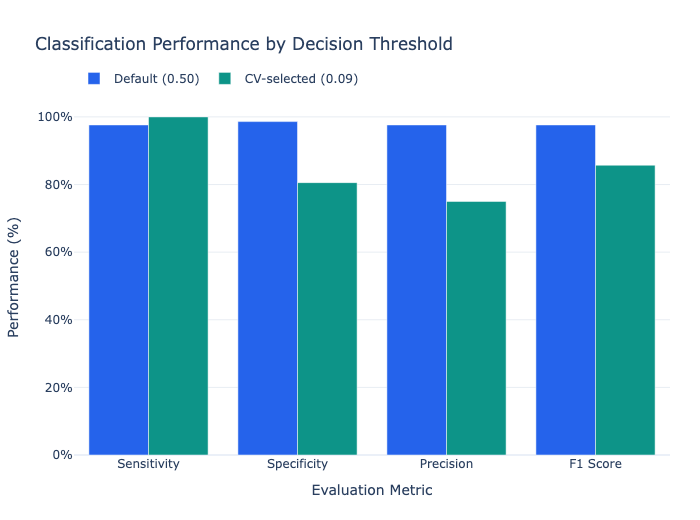

In [35]:
import pandas as pd
import plotly.graph_objects as go

# Performance comparison
performance_df = pd.DataFrame({
    "Metric": [
        "Sensitivity",
        "Specificity",
        "Precision",
        "F1 Score"
    ],
    "Default (0.50)": [
        97.62, 98.61, 97.62, 97.62
    ],
    "CV-selected (0.09)": [
        100.00, 80.56, 75.00, 85.71
    ]
})

fig = go.Figure()

for threshold, color in [
    ("Default (0.50)", "#2563EB"),
    ("CV-selected (0.09)", "#0D9488")
]:
    fig.add_trace(go.Bar(
        x=performance_df["Metric"],
        y=performance_df[threshold],
        name=threshold,
        marker_color=color,
        hovertemplate=(
            "<b>%{x}</b><br>"
            + threshold +
            "<br>Performance: %{y:.2f}%"
            "<extra></extra>"
        )
    ))

fig.update_layout(
    title="Classification Performance by Decision Threshold",
    xaxis_title="Evaluation Metric",
    yaxis_title="Performance (%)",
    barmode="group",
    template="plotly_white",
    hovermode="x unified",
    hoverlabel=dict(font_size=13),
    height=520,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    margin=dict(l=65, r=30, t=100, b=65)
)

fig.update_yaxes(
    range=[0, 105],
    ticksuffix="%",
    gridcolor="#E8EDF3"
)

fig.show()

In [36]:
from sklearn.metrics import brier_score_loss

# Compare malignant-class probability predictions
lr_brier = brier_score_loss(
    y_malignant, lr_prob
)

rf_brier = brier_score_loss(
    y_malignant, rf_prob
)

tuned_rf_brier = brier_score_loss(
    y_malignant, tuned_prob
)

print("MODEL PROBABILITY RELIABILITY")
print("-" * 40)

print(f"Logistic Regression: {lr_brier:.4f}")
print(f"Random Forest:       {rf_brier:.4f}")
print(f"Tuned Random Forest: {tuned_rf_brier:.4f}")

MODEL PROBABILITY RELIABILITY
----------------------------------------
Logistic Regression: 0.0215
Random Forest:       0.0321
Tuned Random Forest: 0.0330


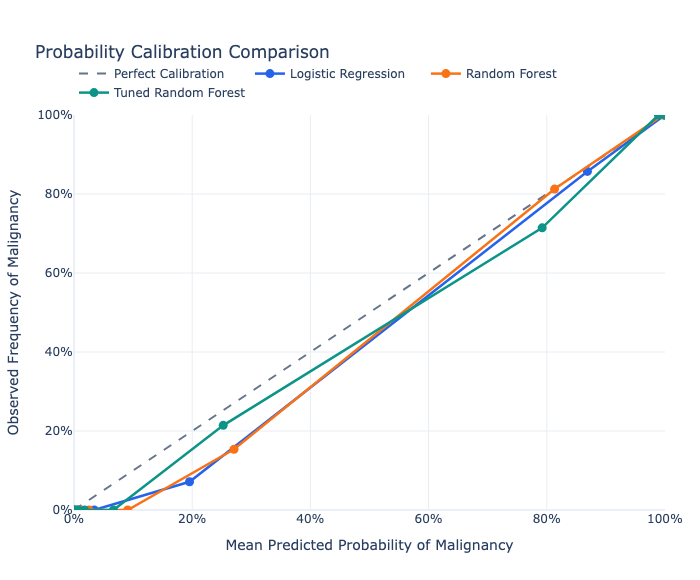

In [37]:
import plotly.graph_objects as go
from sklearn.calibration import calibration_curve

# Models and predicted malignant probabilities
models = {
    "Logistic Regression": (lr_prob, "#2563EB"),
    "Random Forest": (rf_prob, "#F97316"),
    "Tuned Random Forest": (tuned_prob, "#0D9488")
}

fig = go.Figure()

# Perfect calibration reference
fig.add_trace(go.Scatter(
    x=[0, 1],
    y=[0, 1],
    mode="lines",
    name="Perfect Calibration",
    line=dict(color="#64748B", dash="dash", width=2),
    hoverinfo="skip"
))

# Calculate calibration curves
for model_name, (probabilities, color) in models.items():

    observed, predicted = calibration_curve(
        y_malignant,
        probabilities,
        n_bins=8,
        strategy="quantile"
    )

    fig.add_trace(go.Scatter(
        x=predicted,
        y=observed,
        mode="lines+markers",
        name=model_name,
        line=dict(color=color, width=2.5),
        marker=dict(size=9),
        hovertemplate=(
            f"<b>{model_name}</b><br>"
            "Mean predicted probability: %{x:.2%}<br>"
            "Observed malignancy frequency: %{y:.2%}"
            "<extra></extra>"
        )
    ))

fig.update_layout(
    title="Probability Calibration Comparison",
    xaxis_title="Mean Predicted Probability of Malignancy",
    yaxis_title="Observed Frequency of Malignancy",
    template="plotly_white",
    hovermode="closest",
    hoverlabel=dict(font_size=13),
    height=580,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    margin=dict(l=70, r=35, t=115, b=70)
)

fig.update_xaxes(
    range=[0, 1],
    tickformat=".0%",
    gridcolor="#E8EDF3"
)

fig.update_yaxes(
    range=[0, 1],
    tickformat=".0%",
    gridcolor="#E8EDF3"
)

fig.show()

In [38]:
import numpy as np
import pandas as pd

# Examine the Logistic Regression calibration bins
bin_edges = np.quantile(
    lr_prob,
    np.linspace(0, 1, 9)
)

bin_ids = np.digitize(
    lr_prob,
    bin_edges[1:-1],
    right=True
)

calibration_details = pd.DataFrame({
    "Bin": bin_ids + 1,
    "Predicted Probability": lr_prob,
    "Actual Malignancy": np.asarray(y_malignant)
})

bin_summary = (
    calibration_details
    .groupby("Bin")
    .agg(
        Observations=("Actual Malignancy", "size"),
        Mean_Predicted_Probability=("Predicted Probability", "mean"),
        Observed_Malignancy_Rate=("Actual Malignancy", "mean")
    )
    .reset_index()
)

print(bin_summary.to_string(index=False))

 Bin  Observations  Mean_Predicted_Probability  Observed_Malignancy_Rate
   1            15                    0.000048                  0.000000
   2            14                    0.000664                  0.000000
   3            14                    0.006234                  0.000000
   4            14                    0.034204                  0.000000
   5            14                    0.195497                  0.071429
   6            14                    0.868721                  0.857143
   7            14                    0.999826                  1.000000
   8            15                    0.999999                  1.000000


In [39]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

# Cross-validation configuration
calibration_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Sigmoid calibration
sigmoid_model = CalibratedClassifierCV(
    estimator=clone(model),
    method="sigmoid",
    cv=calibration_cv
)

# Isotonic calibration
isotonic_model = CalibratedClassifierCV(
    estimator=clone(model),
    method="isotonic",
    cv=calibration_cv
)

# Fit using training data only
sigmoid_model.fit(X_train, y_train)
isotonic_model.fit(X_train, y_train)

print("Sigmoid calibration completed.")
print("Isotonic calibration completed.")
print("Both models trained using training data only.")

Sigmoid calibration completed.
Isotonic calibration completed.
Both models trained using training data only.


In [40]:
from sklearn.metrics import brier_score_loss
import pandas as pd

# Predict malignant-class probabilities (class 0)
sigmoid_prob = sigmoid_model.predict_proba(X_test)[:, 0]
isotonic_prob = isotonic_model.predict_proba(X_test)[:, 0]

# Compare probability prediction errors
calibration_scores = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Sigmoid Calibration",
        "Isotonic Calibration"
    ],
    "Brier Score": [
        brier_score_loss(y_malignant, lr_prob),
        brier_score_loss(y_malignant, sigmoid_prob),
        brier_score_loss(y_malignant, isotonic_prob)
    ]
})

# Rank models by Brier score (lower is better)
calibration_scores = calibration_scores.sort_values(
    "Brier Score"
).reset_index(drop=True)

calibration_scores["Rank"] = (
    calibration_scores.index + 1
)

print("PROBABILITY CALIBRATION COMPARISON")
print("-" * 50)
print(calibration_scores.to_string(index=False))

PROBABILITY CALIBRATION COMPARISON
--------------------------------------------------
                       Model  Brier Score  Rank
        Isotonic Calibration     0.016735     1
Original Logistic Regression     0.021541     2
         Sigmoid Calibration     0.026412     3


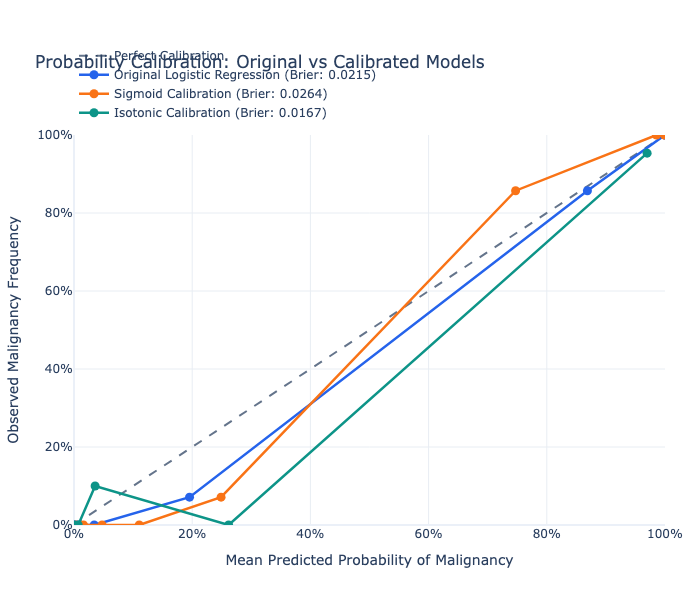

In [41]:
import plotly.graph_objects as go
from sklearn.calibration import calibration_curve

# Model probabilities and Brier scores
models_to_compare = {
    "Original Logistic Regression": {
        "prob": lr_prob,
        "color": "#2563EB"
    },
    "Sigmoid Calibration": {
        "prob": sigmoid_prob,
        "color": "#F97316"
    },
    "Isotonic Calibration": {
        "prob": isotonic_prob,
        "color": "#0D9488"
    }
}

fig = go.Figure()

# Perfect calibration reference line
fig.add_trace(go.Scatter(
    x=[0, 1],
    y=[0, 1],
    mode="lines",
    name="Perfect Calibration",
    line=dict(color="#64748B", dash="dash", width=2),
    hoverinfo="skip"
))

# Calibration curves
for model_name, details in models_to_compare.items():

    probabilities = details["prob"]

    observed, predicted = calibration_curve(
        y_malignant,
        probabilities,
        n_bins=8,
        strategy="quantile"
    )

    brier = brier_score_loss(
        y_malignant,
        probabilities
    )

    fig.add_trace(go.Scatter(
        x=predicted,
        y=observed,
        mode="lines+markers",
        name=f"{model_name} (Brier: {brier:.4f})",
        line=dict(
            color=details["color"],
            width=2.5
        ),
        marker=dict(size=9),
        hovertemplate=(
            f"<b>{model_name}</b><br>"
            "Mean Predicted Probability: %{x:.2%}<br>"
            "Observed Malignancy Rate: %{y:.2%}<br>"
            f"Brier Score: {brier:.4f}"
            "<extra></extra>"
        )
    ))

fig.update_layout(
    title="Probability Calibration: Original vs Calibrated Models",
    xaxis_title="Mean Predicted Probability of Malignancy",
    yaxis_title="Observed Malignancy Frequency",
    template="plotly_white",
    hovermode="closest",
    hoverlabel=dict(font_size=13),
    height=600,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    margin=dict(l=70, r=35, t=135, b=75)
)

fig.update_xaxes(
    range=[0, 1],
    tickformat=".0%",
    gridcolor="#E8EDF3"
)

fig.update_yaxes(
    range=[0, 1],
    tickformat=".0%",
    gridcolor="#E8EDF3"
)

fig.show()

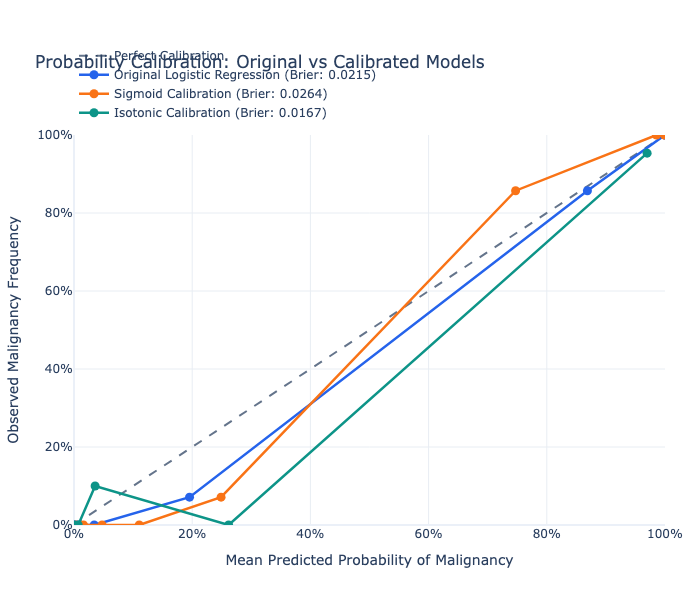

In [42]:
import plotly.graph_objects as go
from sklearn.calibration import calibration_curve

# Model probabilities and Brier scores
models_to_compare = {
    "Original Logistic Regression": {
        "prob": lr_prob,
        "color": "#2563EB"
    },
    "Sigmoid Calibration": {
        "prob": sigmoid_prob,
        "color": "#F97316"
    },
    "Isotonic Calibration": {
        "prob": isotonic_prob,
        "color": "#0D9488"
    }
}

fig = go.Figure()

# Perfect calibration reference line
fig.add_trace(go.Scatter(
    x=[0, 1],
    y=[0, 1],
    mode="lines",
    name="Perfect Calibration",
    line=dict(color="#64748B", dash="dash", width=2),
    hoverinfo="skip"
))

# Calibration curves
for model_name, details in models_to_compare.items():

    probabilities = details["prob"]

    observed, predicted = calibration_curve(
        y_malignant,
        probabilities,
        n_bins=8,
        strategy="quantile"
    )

    brier = brier_score_loss(
        y_malignant,
        probabilities
    )

    fig.add_trace(go.Scatter(
        x=predicted,
        y=observed,
        mode="lines+markers",
        name=f"{model_name} (Brier: {brier:.4f})",
        line=dict(
            color=details["color"],
            width=2.5
        ),
        marker=dict(size=9),
        hovertemplate=(
            f"<b>{model_name}</b><br>"
            "Mean Predicted Probability: %{x:.2%}<br>"
            "Observed Malignancy Rate: %{y:.2%}<br>"
            f"Brier Score: {brier:.4f}"
            "<extra></extra>"
        )
    ))

fig.update_layout(
    title="Probability Calibration: Original vs Calibrated Models",
    xaxis_title="Mean Predicted Probability of Malignancy",
    yaxis_title="Observed Malignancy Frequency",
    template="plotly_white",
    hovermode="closest",
    hoverlabel=dict(font_size=13),
    height=600,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    ),
    margin=dict(l=70, r=35, t=135, b=75)
)

fig.update_xaxes(
    range=[0, 1],
    tickformat=".0%",
    gridcolor="#E8EDF3"
)

fig.update_yaxes(
    range=[0, 1],
    tickformat=".0%",
    gridcolor="#E8EDF3"
)

fig.show()

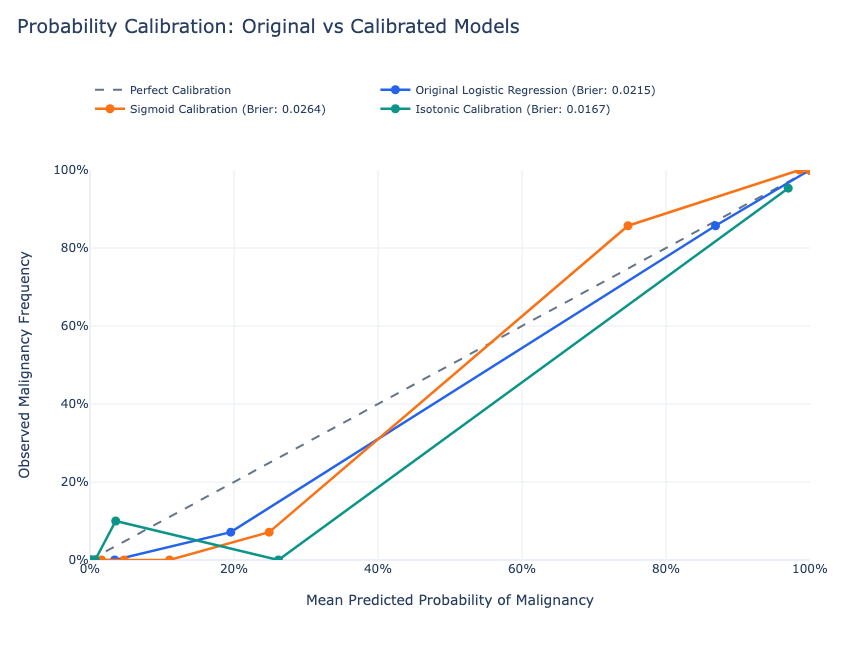

In [43]:
fig.update_layout(
    title=dict(
        text="Probability Calibration: Original vs Calibrated Models",
        x=0.02,
        y=0.97,
        xanchor="left",
        yanchor="top",
        font=dict(size=19)
    ),

    legend=dict(
        orientation="h",
        x=0,
        y=1.12,
        xanchor="left",
        yanchor="bottom",
        font=dict(size=11),
        traceorder="normal"
    ),

    margin=dict(
        l=90,
        r=40,
        t=170,
        b=90
    ),

    height=650,
    width=850,

    font=dict(size=12),
    template="plotly_white"
)

fig.update_xaxes(
    title_standoff=20,
    automargin=True
)

fig.update_yaxes(
    title_standoff=20,
    automargin=True
)

fig.show()

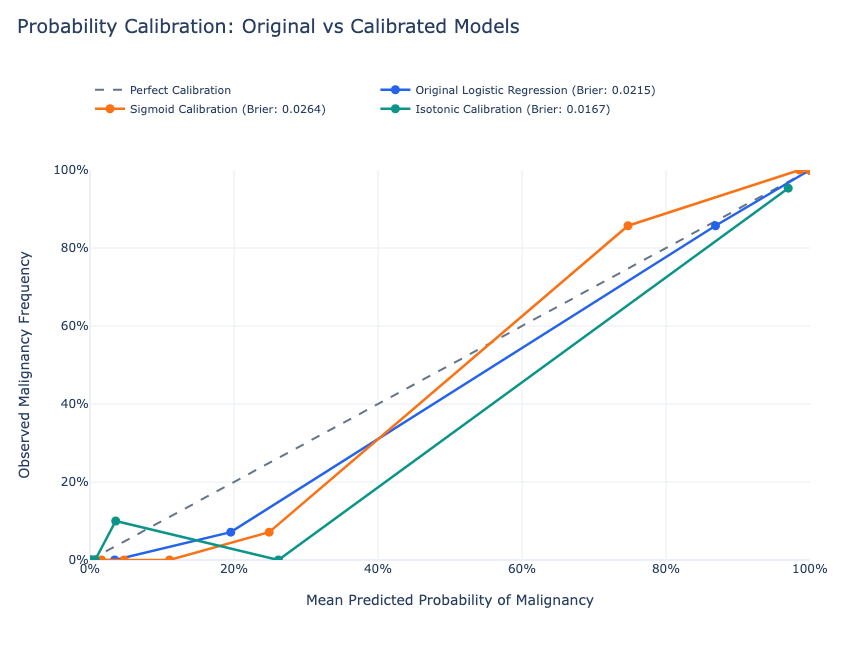

In [44]:
fig.update_layout(
    title=dict(
        text="Probability Calibration: Original vs Calibrated Models",
        x=0.02,
        y=0.97,
        xanchor="left",
        yanchor="top",
        font=dict(size=19)
    ),

    legend=dict(
        orientation="h",
        x=0,
        y=1.12,
        xanchor="left",
        yanchor="bottom",
        font=dict(size=11),
        traceorder="normal"
    ),

    margin=dict(
        l=90,
        r=40,
        t=170,
        b=90
    ),

    height=650,
    width=850,

    font=dict(size=12),
    template="plotly_white"
)

fig.update_xaxes(
    title_standoff=20,
    automargin=True
)

fig.update_yaxes(
    title_standoff=20,
    automargin=True
)

fig.show()